# Telecom Customer Churn Analysis and Prediction
+ Customer churn is a major challenge in the telecommunications industry because losing customers can reduce revenue and increase customer acquisition costs.

+ We will perform Exploratory Data Analysis (EDA) to identify patterns and factors associated with customer churn. We will then build and evaluate machine learning classification models to predict whether a customer is likely to leave the telecom service.

+ Target Variable: Churn — indicates whether a customer has left the service (Yes) or stayed (No).

# **Import libraries and load the data**

In [3]:
# Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import os

In [4]:
import kagglehub
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

print("File directory of dataset ", path)

# Load the Dataset
df = pd.read_csv("/kaggle/input/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Print after data load sucessfully
print("\nDataset loaded successfully.")


Using Colab cache for faster access to the 'telco-customer-churn' dataset.
File directory of dataset  /kaggle/input/telco-customer-churn

Dataset loaded successfully.


## 1. Understand the data

+ Shape, columns, data types, duplicates and data quality.

In [5]:
# Numbers of Rows and Columns
print("Shape of data: ", df.shape)

Shape of data:  (7043, 21)


In [6]:
# Inspaction first five row
display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
# Check columns names, data-type and null values

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Here we found Total Charges is a object column. First we will change it into a numeric column then we will check any missing value in data

In [8]:
# Change TottalCharges into numeric data type
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Check for missing values in the 'TotalCharges' column
missing_values = df['TotalCharges'].isnull().sum()

# output missing value
missing_values

np.int64(11)

+ Here we found 11 missing value in Total charges

In [9]:
# check data missing value
df.isnull().sum().sort_values(ascending=False)

,0
TotalCharges,11
gender,0
SeniorCitizen,0
Partner,0
customerID,0
Dependents,0
tenure,0
MultipleLines,0
PhoneService,0
OnlineSecurity,0


+ Now we will check that null value in TotalCharges Customer churn and Monthly Charges

In [10]:
display(df[df['TotalCharges'].isnull()][['tenure', 'Churn', 'MonthlyCharges', 'TotalCharges']])

,tenure,Churn,MonthlyCharges,TotalCharges
488,0,No,52.55,NaN
753,0,No,20.25,NaN
936,0,No,80.85,NaN
1082,0,No,25.75,NaN
1340,0,No,56.05,NaN
3331,0,No,19.85,NaN
3826,0,No,25.35,NaN
4380,0,No,20.00,NaN
5218,0,No,19.70,NaN
6670,0,No,73.35,NaN


+ Also check tenure 0 in any other in data

In [11]:
# Check Tenure is 0 present in any index number in data
df[df['tenure'] == 0].index

Index([488, 753, 936, 1082, 1340, 3331, 3826, 4380, 5218, 6670, 6754], dtype='int64')

+ The dataset contained 11 records with missing TotalCharges values. After investigation, these records were found to have tenure = 0, indicating zero months of recorded customer tenure. Since the actual total charges could not be reliably determined from the available data, I decided not to impute these values using MonthlyCharges, as doing so could introduce inaccurate information. Therefore, I removed these 11 records. This affected only approximately 0.16% of the original dataset, so the impact on the overall dataset size was minimal.

In [12]:
# Drop null value of
df.dropna(inplace=True)


# Data Visualization

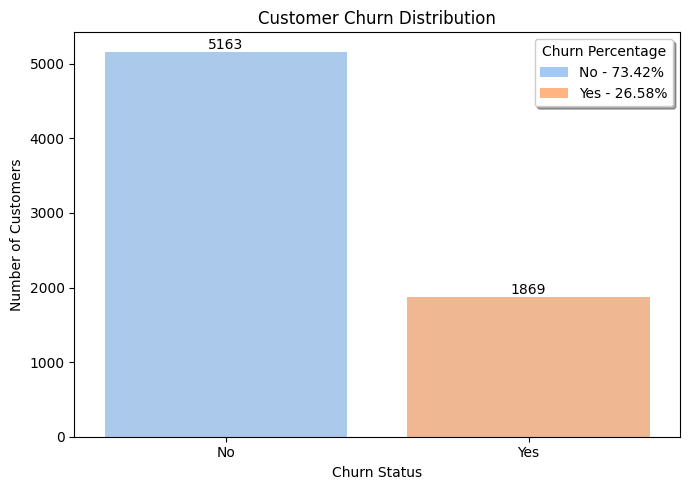

In [13]:
# Count customers in each churn category
churn_counts = df["Churn"].value_counts().reindex(["No", "Yes"])

# Calculate percentage of customers in each class
churn_percent = (
    df["Churn"]
    .value_counts(normalize=True)
    .reindex(["No", "Yes"]) * 100
)

# Plot chart
plt.figure(figsize=(7, 5))
ax = sns.barplot(
    x=churn_counts.index,
    y=churn_counts.values,
    hue= churn_counts.index,
    palette="pastel",
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

ax.legend(
    handles=[
        Patch(facecolor=sns.color_palette("pastel")[0],
              label=f"No - {churn_percent['No']:.2f}%"),
        Patch(facecolor=sns.color_palette("pastel")[1],
              label=f"Yes - {churn_percent['Yes']:.2f}%")
    ],
    title="Churn Percentage",
    shadow=True,
    loc="upper right"
)


plt.tight_layout()
plt.show()



**Compare churn rates by tenure groups**

,TenureGroup,ChurnRate
0,0-12 months,47.68
1,13-24 months,28.71
2,25-48 months,20.39
3,49-72 months,9.51


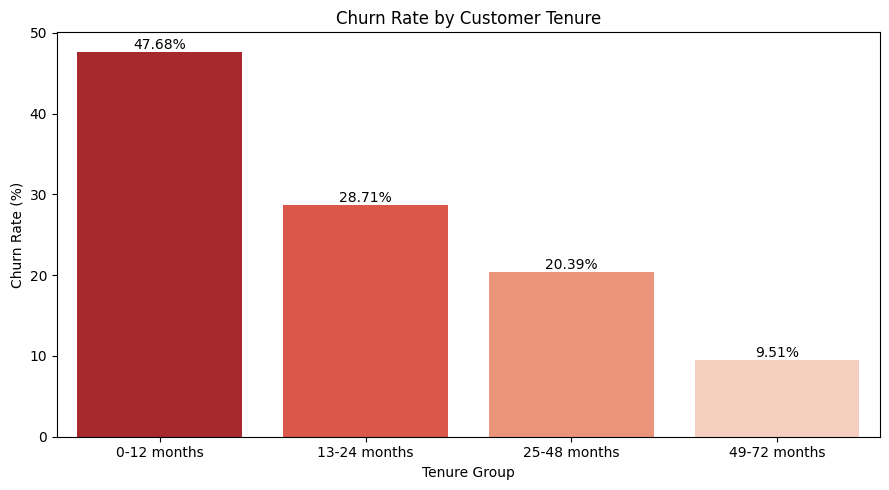

In [14]:
# Create tenure groups for easier interpretation
tenure_bins = [0, 12, 24, 48, 72]
tenure_labels = [
    "0-12 months",
    "13-24 months",
    "25-48 months",
    "49-72 months"
]

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=tenure_bins,
    labels=tenure_labels,
    include_lowest=True
)

# Calculate churn rate within each tenure group
tenure_churn = (
    df.groupby("TenureGroup", observed=False)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

display(tenure_churn.round(2))

plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=tenure_churn,
    x="TenureGroup",
    y="ChurnRate",
    hue="TenureGroup",
    palette="Reds_r",

)

# show number of customer on very bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")



plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

+ Churn is highest during the first 12 months. After 12 months, the churn rate drops by approximately half, suggesting that longer-tenured customers are less likely to leave.

+ **Compare churn rates for the most important categorical features**
+ Start with contract, internet service, payment method, and technical support.

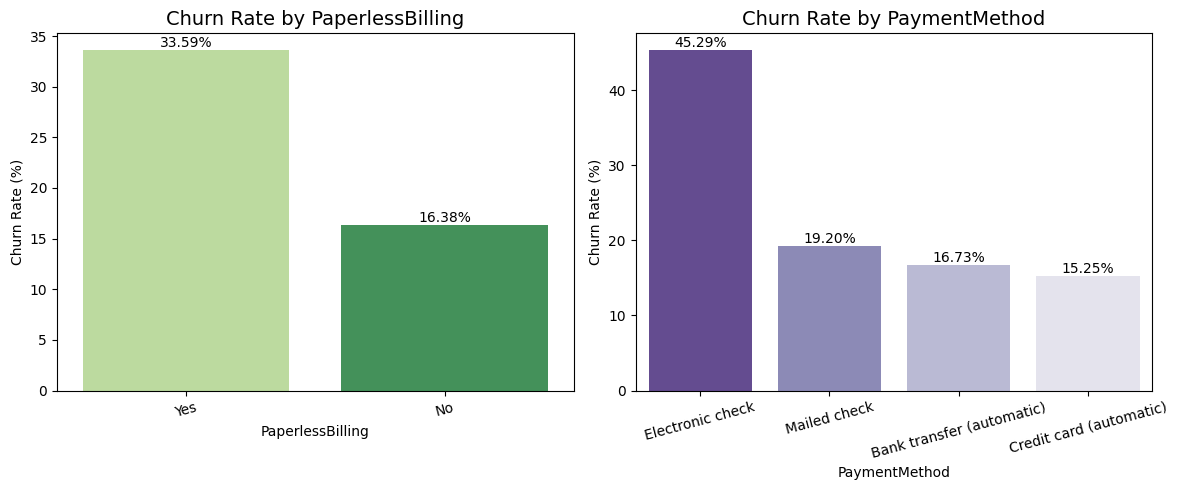

In [15]:
payment_group = [
    "PaperlessBilling",
    "PaymentMethod",
    ]

# Set Plot color
palettes = ["YlGn", "Purples_r"]

# Plot size and number
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col, palette_name in zip(axes.flat, payment_group, palettes):

    # Calculate the churn rate within each category
    plot_data = (
        df.groupby(col, dropna=False)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .reset_index(name="ChurnRate")
        .sort_values("ChurnRate", ascending=False)
    )

    # Plot bars
    sns.barplot(data=plot_data, x=col, y="ChurnRate", hue=col, palette=palette_name, ax=ax,)

# show number on every bar
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f%%")


    ax.set_title(f"Churn Rate by {col}", fontsize=14)
    ax.set_ylabel("Churn Rate (%)")
    ax.set_xlabel(col)
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

+ **Contract:** Customers on month-to-month contracts appear to have a higher churn rate than customers on longer-term contracts.

- **Paperless Billing:** Customers using paperless billing appear to have a higher churn rate than customers not using paperless billing.
- **Payment Method:** Customers using electronic checks show a relatively high churn rate compared with customers using other payment methods.


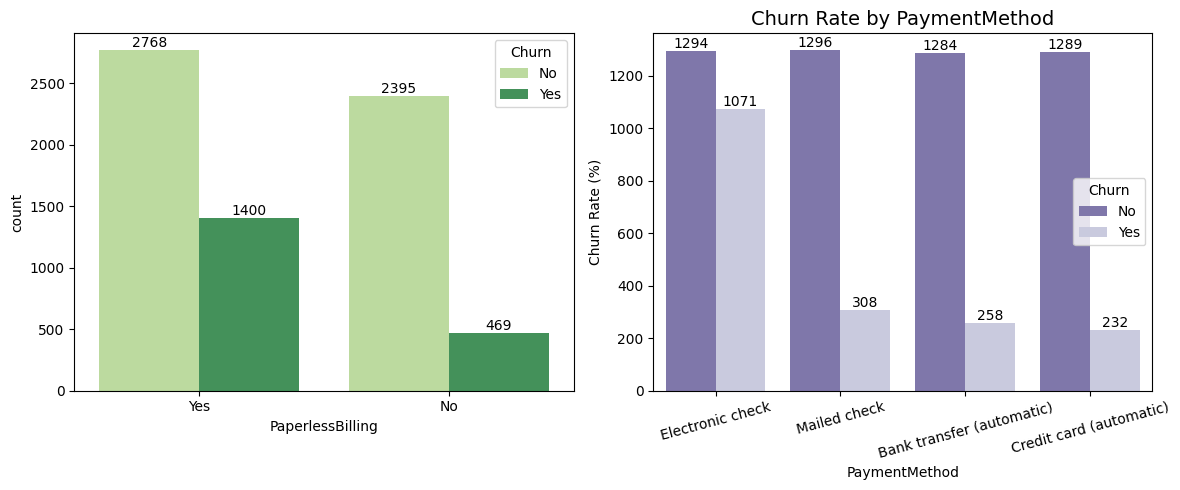

In [17]:
# Plot size and number
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col, palette_name in zip(axes.flat, payment_group, palettes):
  # Count plot
  ax = sns.countplot(data=df, x=col, hue="Churn", palette=palette_name, ax=ax)

  # show number on every bar
  for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

ax.set_title(f"Churn Rate by {col}", fontsize=14)
ax.set_ylabel("Churn Rate (%)")
ax.set_xlabel(col)
ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

# **Comapre churn for every category**

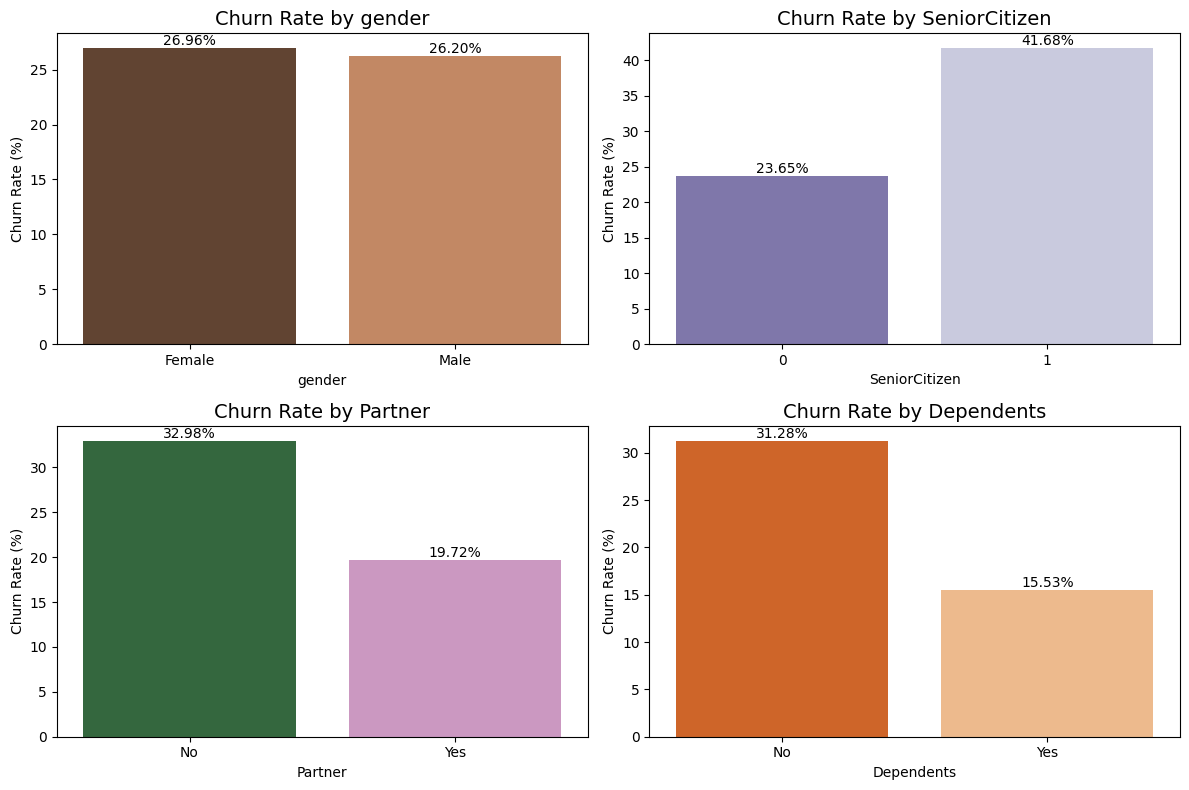

In [18]:
# Count Plot
family_cols = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
]

# Set Plot color
palettes = ["copper", "Purples_r", "cubehelix", "Oranges_r"]

# Plot by for
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col, palette_name in zip(axes.flat, family_cols, palettes):

  # Calculate the churn rate within each category
  plot_data1 = (
      df.groupby(col, dropna=False)["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .reset_index(name="ChurnRate")
      .sort_values("ChurnRate", ascending=False)
  )
  # Bar plot
  sns.barplot(data=plot_data1, x=col, y="ChurnRate", hue=col, palette=palette_name, ax=ax, legend=False)

  # Show percentage on every bar
  for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

  ax.set_title(f"Churn Rate by {col}", fontsize=14)
  ax.set_ylabel("Churn Rate (%)")
  ax.set_xlabel(col)


plt.tight_layout()
plt.show()

+ **Gender:** Churn rates are nearly identical across genders, suggesting little association between gender and churn.

+ **Senior Citizen:** Senior citizens appear to have a lower churn rate than non-senior customers.

+ **Partner:** Customers without partners appear to have a higher churn rate than customers with partners.

+ **Dependents:** Customers without dependents appear to have a higher churn rate than customers with dependents.

**Churn by Services**


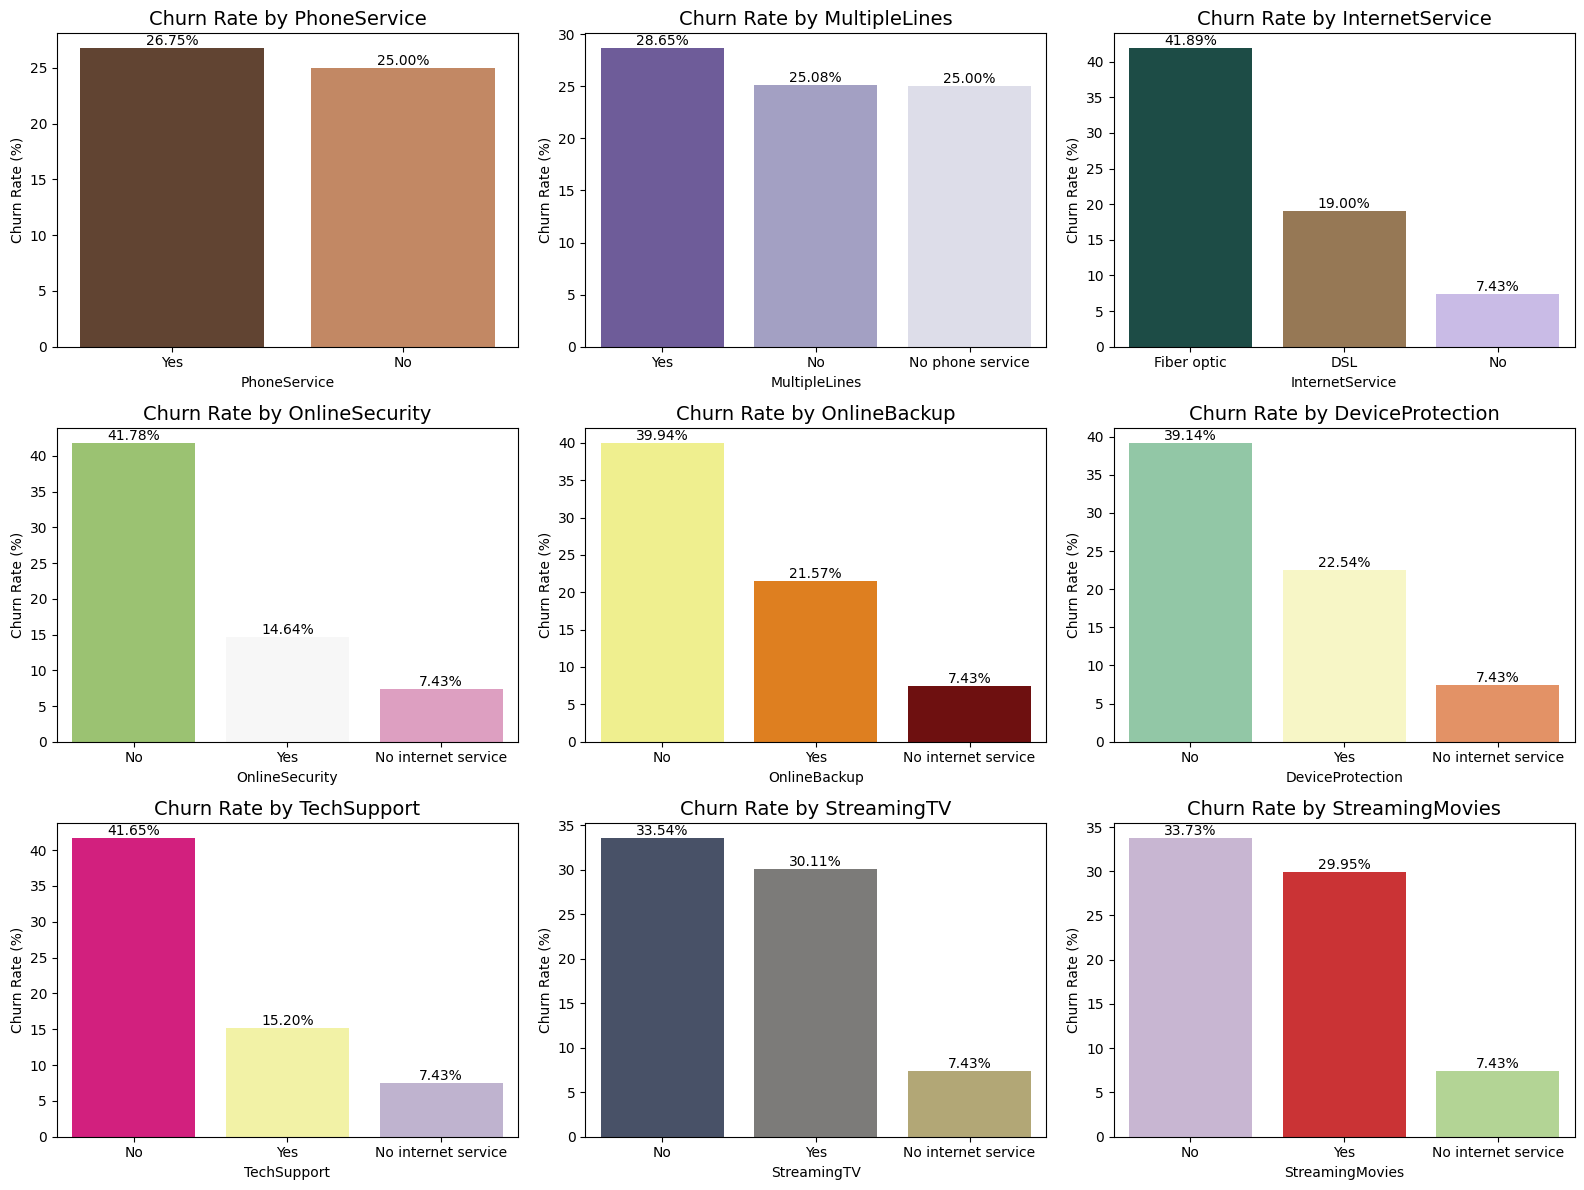

In [19]:
# Churn by services
service_cols = [
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
]

# Separate color for all charts
palettes = ["copper", "Purples_r", "cubehelix", "PiYG_r", "afmhot_r", "Spectral_r", "Accent_r", "cividis", "Paired_r"]

# Plot Size and numbers of plot
fig, axes = plt.subplots(3, 3, figsize=(16, 12))

for ax, col, palette_name in zip(axes.flat, service_cols, palettes):
  # Calculate the churn rate within each category
  plot_data2 = (
      df.groupby(col, dropna=False)["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .reset_index(name="ChurnRate")
      .sort_values("ChurnRate", ascending=False)
  )

  # barplot ChurnRate
  sns.barplot(data=plot_data2, x=col, y="ChurnRate", hue=col, palette=palette_name, ax=ax, legend=False)

  # Count number on every bar
  for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

  ax.set_title(f"Churn Rate by {col}", fontsize=14)
  ax.set_ylabel("Churn Rate (%)")
  ax.set_xlabel(col)


plt.tight_layout()
plt.show()

+ **Phone Service:** Phone service minor diffrance in hte churn rate.
+ **Multiple Lines:** customer have multiple lines minor diffrance in churn rate
+ **Internet Service:** customer have Fiber Optic service high churn rate according to DSL service.
+ **Online Backup:** Customer no online backup service his churn rate is high.
+ **Device Protection:** customer without device proction the churn rate is high according to with device proction.
+ **Tech Support:** Customers without tech support appear to have a higher churn rate than those with tech support.
+ **Streaming TV:** Customer have no internet service his churan rate very low according to customer streaming tv service use or not.
+ **Streaming Movies:** Customer have no internet service his churan rate very low according to customer streaming movies service use or not.

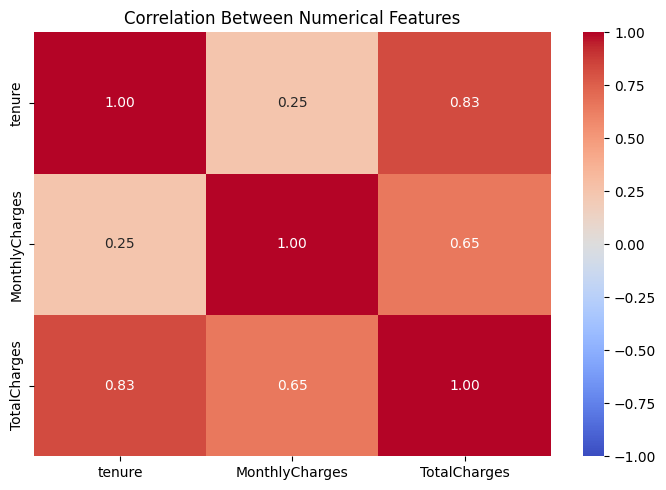

In [22]:
# Use numeric columns for correlation analysis
corr_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

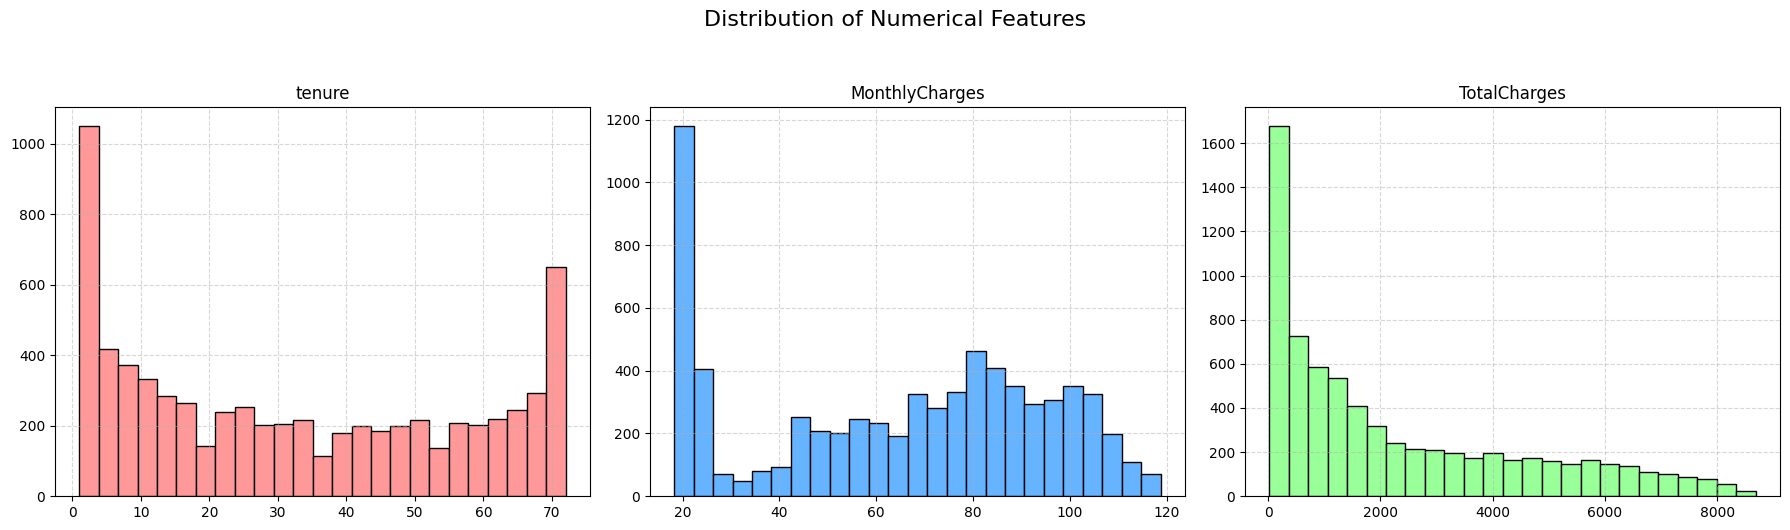

In [23]:
# Numerical features to investigate
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
colors = ["#ff9999", "#66b3ff", "#99ff99"]

# Create a subplot grid
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot individual histograms with distinct colors
for i, (col, color) in enumerate(zip(numeric_cols, colors)):
    axes[i].hist(
        df[col].dropna(),
        bins=25,
        edgecolor="black",
        color=color
    )
    axes[i].set_title(col)
    axes[i].grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Distribution of Numerical Features", y=1.05, fontsize=16)
plt.tight_layout()
plt.show()

/tmp/ipykernel_568/1700746040.py:7: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.kdeplot(
/tmp/ipykernel_568/1700746040.py:7: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.kdeplot(
/tmp/ipykernel_568/1700746040.py:7: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.kdeplot(


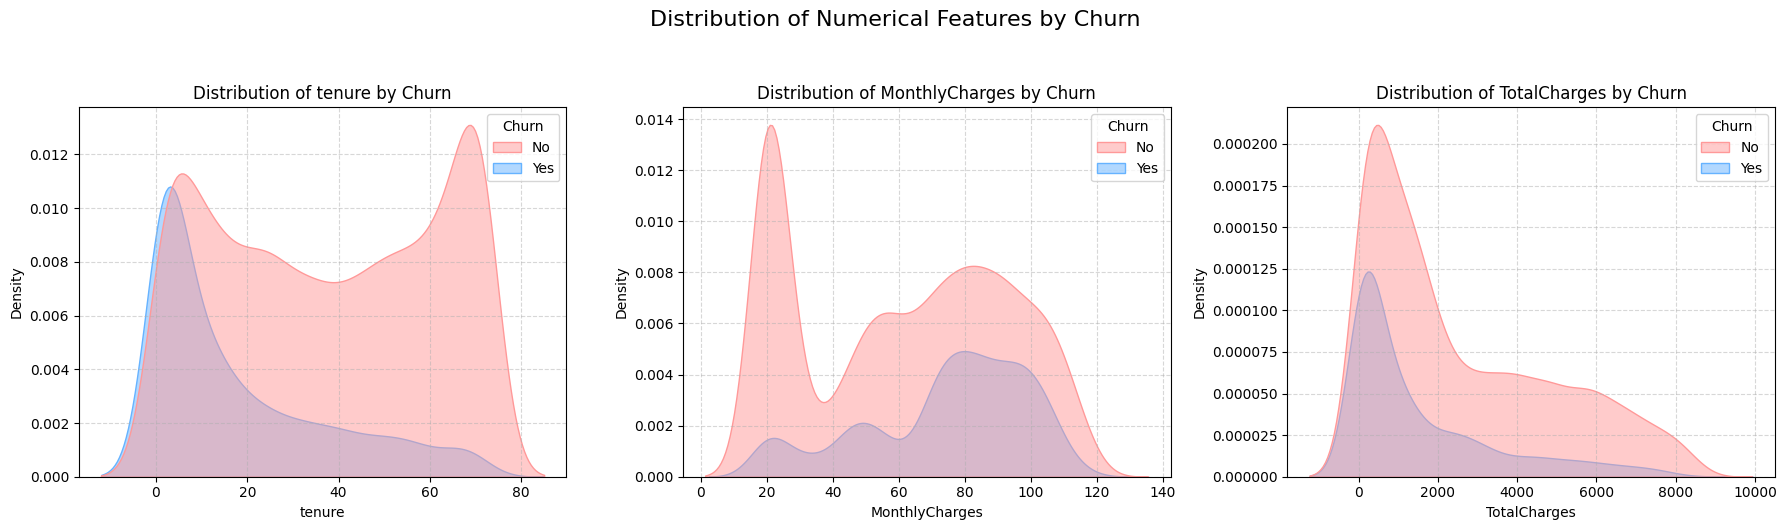

In [33]:
# Distribution of MonthyCharges, TotalCharges and Tenure by churn
# Create a subplot
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot individual
for i, (col, color) in enumerate(zip(numeric_cols, colors)):
    sns.kdeplot(
        data=df,
        x=col,
        hue="Churn",
        fill=True,
        palette=colors,
        alpha=0.5,
        ax=axes[i]
    )
    axes[i].set_title(f"Distribution of {col} by Churn")
    axes[i].grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Distribution of Numerical Features by Churn", y=1.05, fontsize=16)
plt.tight_layout()
plt.show()

In [35]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0-12 months
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,25-48 months
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0-12 months
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,25-48 months
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0-12 months


In [38]:
# Split data into train and test
from sklearn.model_selection import train_test_split

X = df.drop(["Churn", "TenureGroup", "customerID"], axis=1)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [40]:
# Identify numerical and categorical features
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

In [45]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, f1_score, confusion_matrix

# Logistic Regression and SVM — with StandardScaler

scaled_preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

logistic_model = Pipeline([
    ("preprocessor", scaled_preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

svm_model = Pipeline([
    ("preprocessor", scaled_preprocessor),
    ("classifier", SVC(kernel="rbf", random_state=42))
])

label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train)
y_test = label_encoder.transform(y_test)


logistic_model.fit(X_train, y_train)
svm_model.fit(X_train, y_train)

logistic_preds = logistic_model.predict(X_test)
svm_preds = svm_model.predict(X_test)

logistic_accuracy = accuracy_score(y_test, logistic_preds)
svm_accuracy = accuracy_score(y_test, svm_preds)

print("Logistic Regression Accuracy:", logistic_accuracy)
print("SVM Accuracy:", svm_accuracy)

print("\nLogistic Regression Classification Report:")
print(classification_report(y_test, logistic_preds))

print("\nSVM Classification Report:")
print(classification_report(y_test, svm_preds))



Logistic Regression Accuracy: 0.7874911158493249
SVM Accuracy: 0.7903340440653873

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1033
           1       0.62      0.52      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407


SVM Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.91      0.86      1033
           1       0.64      0.47      0.54       374

    accuracy                           0.79      1407
   macro avg       0.74      0.69      0.70      1407
weighted avg       0.78      0.79      0.78      1407



In [46]:
# Random Forest and XGBoost — without StandardScaler

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

unscaled_preprocessor = ColumnTransformer([
    ("num", "passthrough", numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

rf_model = Pipeline([
    ("preprocessor", unscaled_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

xgb_model = Pipeline([
    ("preprocessor", unscaled_preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42
    ))
])

# Fit model on data
rf_model.fit(X_train, y_train)
xgb_model.fit(X_train, y_train)

rf_preds = rf_model.predict(X_test)
xgb_preds = xgb_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_preds)
xgb_accuracy = accuracy_score(y_test, xgb_preds)

print("Random Forest Accuracy:", rf_accuracy)
print("XGBoost Accuracy:", xgb_accuracy)

print("\nRandom Forest Classification Report:")
print(classification_report(y_test, rf_preds))

print("\nXGBoost Classification Report:")
print(classification_report(y_test, xgb_preds))


Random Forest Accuracy: 0.7803837953091685
XGBoost Accuracy: 0.7981520966595593

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.90      0.86      1033
           1       0.62      0.45      0.52       374

    accuracy                           0.78      1407
   macro avg       0.72      0.68      0.69      1407
weighted avg       0.77      0.78      0.77      1407


XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1033
           1       0.65      0.52      0.58       374

    accuracy                           0.80      1407
   macro avg       0.74      0.71      0.72      1407
weighted avg       0.79      0.80      0.79      1407



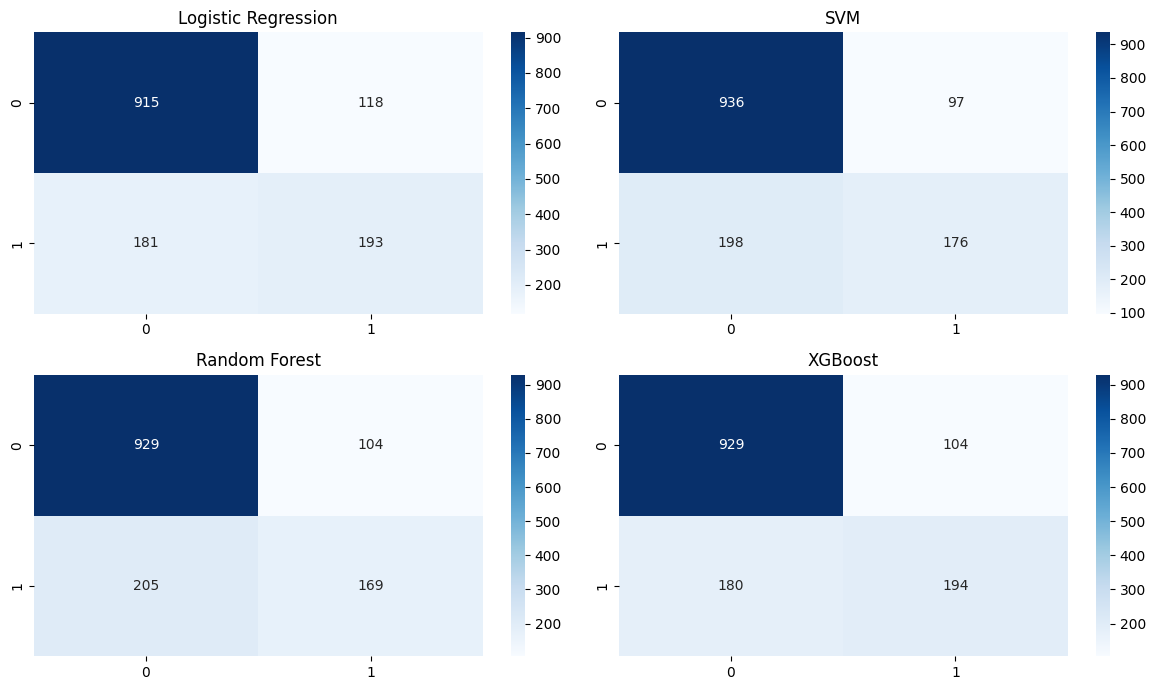

In [53]:
# Plot all result confision metrix
fig, axes = plt.subplots(2, 2, figsize=(12, 7))


for ax, model, title in zip(axes.flat, [logistic_model, svm_model, rf_model, xgb_model], ["Logistic Regression", "SVM", "Random Forest", "XGBoost"]):
  y_pred = model.predict(X_test)
  cm = confusion_matrix(y_test, y_pred)
  sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax)
  ax.set_title(title)
plt.tight_layout()
plt.show()


In [55]:
# Create score list using the accuracy variables defined earlier
results = [
    {"Model": "Logistic Regression", "Accuracy": logistic_accuracy},
    {"Model": "SVM", "Accuracy": svm_accuracy},
    {"Model": "Random Forest", "Accuracy": rf_accuracy},
    {"Model": "XGBoost", "Accuracy": xgb_accuracy}
]

# Create score table
score_df = pd.DataFrame(results)

# Sort accuracy in descending order
score_df = score_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

# Display scores
print("\nModel Accuracy Comparison (High to Low):")
print(score_df.to_string(index=False))

# Optional: display accuracy as percentage
score_df["Accuracy"] = (score_df["Accuracy"] * 100).round(2).astype(str) + "%"

print("\nModel Score Table:")
print(score_df.to_string(index=False))


Model Accuracy Comparison (High to Low):
              Model  Accuracy
            XGBoost  0.798152
                SVM  0.790334
Logistic Regression  0.787491
      Random Forest  0.780384

Model Score Table:
              Model Accuracy
            XGBoost   79.82%
                SVM   79.03%
Logistic Regression   78.75%
      Random Forest   78.04%
